# 06 · Ensembles, neural networks and a UK-National-Grid-style meta-learner
**Level 3 · Predictive analytics (supervised)** &nbsp;|&nbsp; Course link: *Module 4 – forecasting with ensemble methods
and neural networks*

Notebook 05 used linear models. Here we use **non-linear** learners and combine them:
1. single learners: decision tree, random forest, gradient boosting, support-vector regression, neural network (GPU);
2. **why no single model wins everywhere**: errors by season;
3. the **UK National Grid PV-forecasting architecture**: parallel weak learners + a meta neural network that, given the
   weather context, decides how much to trust each learner;
4. **uncertainty**: prediction intervals with quantile gradient boosting;
5. **demand forecasting** with recent-load features.

In [1]:
import warnings, time
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error
from energy_ai import gb_dataset, clean_load, get_device, set_seed, style
style(); set_seed(0)
device = get_device()

df = gb_dataset()
df["load_mw"] = clean_load(df.load_mw)[0]

def features(d):
    X = d[["shortwave_radiation", "direct_radiation", "diffuse_radiation", "temperature_2m", "cloud_cover",
           "solar_elevation", "doy_sin", "doy_cos", "hour_sin", "hour_cos"]].copy()
    X["ghi_x_sin_elev"] = d.shortwave_radiation * np.sin(np.radians(d.solar_elevation.clip(lower=0)))
    return X

# training 2017 + Jan–Jun 2018 | validation Jul–Dec 2018 (for the meta-learner) | test 2019
fit, val, test = df.loc["2017":"2018-06"], df.loc["2018-07":"2018-12"], df.loc["2019"]
Xf, Xv, Xt = features(fit), features(val), features(test)
yf, yv, yt = fit.solar_mw, val.solar_mw, test.solar_mw
CAP = df.loc["2017":"2018"].solar_mw.max()
rmse = lambda y, p: np.sqrt(mean_squared_error(y, p))
print("train / validation / test hours:", len(Xf), len(Xv), len(Xt))

Using device: xpu (Intel(R) UHD Graphics)
train / validation / test hours: 13092 4416 8760


## 1. The weak learners
* **Decision tree:** splits the feature space into boxes and predicts the mean in each box (interpretable, unstable).
* **Random forest:** averages hundreds of trees trained on bootstrap samples with random feature subsets (bagging →
  lower variance).
* **Gradient boosting:** adds small trees one after another, each fitting the errors of the previous ensemble
  ($F_m = F_{m-1} + \nu\,h_m$).
* **SVR:** fits a function within an $\varepsilon$-tube using an RBF kernel (needs scaled inputs, scales poorly with $n$).
* **Neural network (MLP):** layers of weighted sums and ReLUs, trained by backpropagation (on the Intel GPU).

In [2]:
class MLPRegressorTorch:
    """Small PyTorch MLP with a scikit-learn-like interface, trained on the available GPU."""
    def __init__(self, hidden=(64, 64), epochs=300, lr=3e-3):
        self.hidden, self.epochs, self.lr = hidden, epochs, lr
    def fit(self, X, y):
        self.sx, self.sy = StandardScaler().fit(X), (float(np.mean(y)), float(np.std(y)))
        Xt_ = torch.tensor(self.sx.transform(X), dtype=torch.float32, device=device)
        yt_ = torch.tensor(((np.asarray(y) - self.sy[0]) / self.sy[1])[:, None], dtype=torch.float32, device=device)
        layers, d = [], X.shape[1]
        for h in self.hidden:
            layers += [nn.Linear(d, h), nn.ReLU()]; d = h
        self.net = nn.Sequential(*layers, nn.Linear(d, 1)).to(device)
        opt = torch.optim.Adam(self.net.parameters(), lr=self.lr)
        for _ in range(self.epochs):
            for b in torch.randperm(len(Xt_)).to(device).split(1024):  # big batches suit the GPU; permutation made on CPU
                loss = ((self.net(Xt_[b]) - yt_[b]) ** 2).mean()
                opt.zero_grad(); loss.backward(); opt.step()
        return self
    def predict(self, X):
        with torch.no_grad():
            out = self.net(torch.tensor(self.sx.transform(X), dtype=torch.float32, device=device)).cpu().numpy()[:, 0]
        return out * self.sy[1] + self.sy[0]

learners = {
    "decision tree": DecisionTreeRegressor(max_depth=12, min_samples_leaf=10, random_state=0),
    "random forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=5, max_features=0.6, n_jobs=-1, random_state=0),
    "gradient boosting": HistGradientBoostingRegressor(max_iter=600, learning_rate=0.05, max_leaf_nodes=31, random_state=0),
    "SVR (RBF)": make_pipeline(StandardScaler(), SVR(C=3000, epsilon=50, gamma="scale")),
    "neural network (GPU)": MLPRegressorTorch(),
}
preds_v, preds_t, rows = {}, {}, []
for name, m in learners.items():
    t0 = time.perf_counter()
    if name.startswith("SVR"):                       # SVR cost grows ~n², train on a subsample
        sub = Xf.sample(6000, random_state=0); m.fit(sub, yf.loc[sub.index])
    else:
        m.fit(Xf, yf)
    preds_v[name], preds_t[name] = m.predict(Xv).clip(0), m.predict(Xt).clip(0)
    rows.append({"model": name, "test RMSE [MW]": rmse(yt, preds_t[name]), "nRMSE [%]": 100 * rmse(yt, preds_t[name]) / CAP,
                 "train time [s]": time.perf_counter() - t0})
single = pd.DataFrame(rows).set_index("model")
display(single.round(2))

,test RMSE [MW],nRMSE [%],train time [s]
model,,,
decision tree,442.13,4.91,0.22
random forest,372.35,4.13,2.37
gradient boosting,394.09,4.37,4.49
SVR (RBF),383.11,4.25,4.13
neural network (GPU),399.59,4.43,33.06


## 2. No single model wins everywhere
The course's UK example: winter (low sun, more wind and clouds) and summer behave differently. We compare errors per
season and per sky condition.

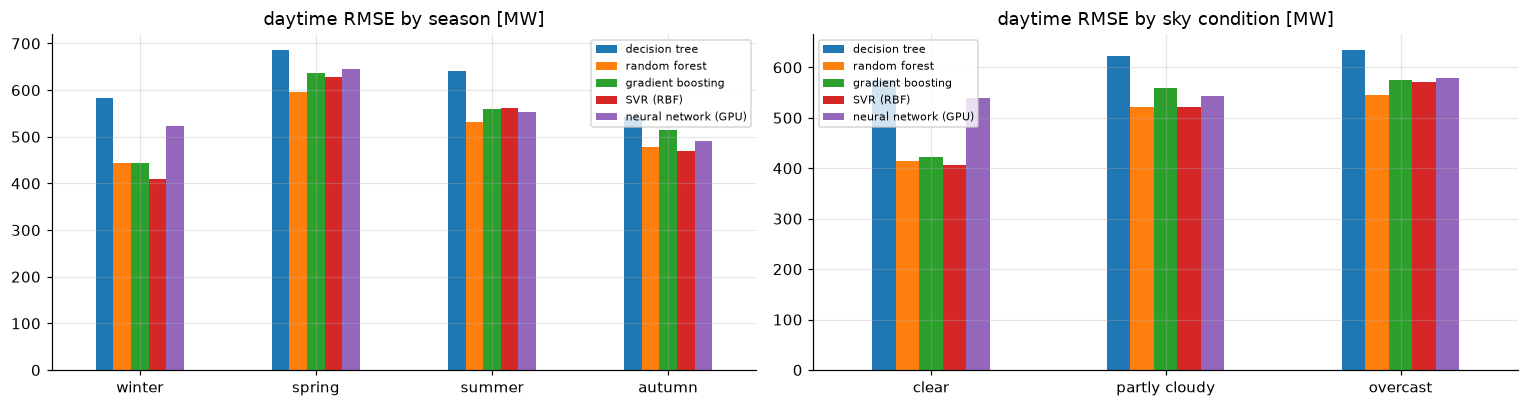

best learner per season: {'winter': 'SVR (RBF)', 'spring': 'random forest', 'summer': 'random forest', 'autumn': 'SVR (RBF)'}
best learner per sky   : {'clear': 'SVR (RBF)', 'partly cloudy': 'SVR (RBF)', 'overcast': 'random forest'}


In [3]:
season = pd.Series(np.select([test.month.isin([12, 1, 2]), test.month.isin([3, 4, 5]), test.month.isin([6, 7, 8])],
                             ["winter", "spring", "summer"], "autumn"), index=test.index)
sky = pd.cut(test.cloud_cover, [-1, 30, 70, 101], labels=["clear", "partly cloudy", "overcast"])
day = test.solar_elevation > 0
by_season = pd.DataFrame({n: [rmse(yt[(season == s) & day], p[((season == s) & day).values]) for s in ["winter", "spring", "summer", "autumn"]]
                          for n, p in preds_t.items()}, index=["winter", "spring", "summer", "autumn"])
by_sky = pd.DataFrame({n: [rmse(yt[(sky == s) & day], p[((sky == s) & day).values]) for s in sky.cat.categories]
                       for n, p in preds_t.items()}, index=sky.cat.categories)
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
by_season.plot.bar(ax=ax[0], rot=0); ax[0].set(title="daytime RMSE by season [MW]")
by_sky.plot.bar(ax=ax[1], rot=0); ax[1].set(title="daytime RMSE by sky condition [MW]")
for a in ax: a.legend(fontsize=7)
plt.tight_layout(); plt.show()
print("best learner per season:", by_season.idxmin(axis=1).to_dict())
print("best learner per sky   :", by_sky.idxmin(axis=1).to_dict())

## 3. The UK National Grid architecture: a meta neural network over weak learners
Layer 1: the weak learners above, trained in parallel. Layer 2: a **meta neural network** that looks at the *context*
$c$ (season, time of day, cloudiness, irradiance) and outputs weights $\alpha_m(c)$ (a softmax, so they are positive
and sum to 1):
$$\hat y(x, c) = \sum_{m=1}^{M} \alpha_m(c)\,\hat y_m(x),\qquad \alpha(c)=\mathrm{softmax}(g_\phi(c))$$
The meta network is trained on the **validation period** (predictions the base learners did not see during training),
otherwise it would learn to trust whichever model overfits most.

In [4]:
names = list(preds_t)
ctx_cols = ["doy_sin", "doy_cos", "hour_sin", "hour_cos", "cloud_cover", "shortwave_radiation", "temperature_2m"]
sc_ctx = StandardScaler().fit(val[ctx_cols])
Cv = torch.tensor(sc_ctx.transform(val[ctx_cols]), dtype=torch.float32, device=device)
Ct = torch.tensor(sc_ctx.transform(test[ctx_cols]), dtype=torch.float32, device=device)
Pv = torch.tensor(np.column_stack([preds_v[n] for n in names]) / CAP, dtype=torch.float32, device=device)
Pt = torch.tensor(np.column_stack([preds_t[n] for n in names]) / CAP, dtype=torch.float32, device=device)
Yv = torch.tensor(yv.values / CAP, dtype=torch.float32, device=device)

gate = nn.Sequential(nn.Linear(len(ctx_cols), 32), nn.Tanh(), nn.Linear(32, len(names))).to(device)
opt = torch.optim.Adam(gate.parameters(), lr=3e-3, weight_decay=1e-4)
for epoch in range(800):
    w = torch.softmax(gate(Cv), dim=1)
    loss = (((w * Pv).sum(1) - Yv) ** 2).mean()
    opt.zero_grad(); loss.backward(); opt.step()
with torch.no_grad():
    W = torch.softmax(gate(Ct), dim=1).cpu().numpy()
meta_pred = (W * Pt.cpu().numpy()).sum(1) * CAP

avg_pred = np.mean([preds_t[n] for n in names], axis=0)
from scipy.optimize import nnls
coef, _ = nnls(np.column_stack([preds_v[n] for n in names]), yv.values)
stack_pred = np.column_stack([preds_t[n] for n in names]) @ coef
best_single = single["test RMSE [MW]"].idxmin()
comp = pd.DataFrame({
    "test RMSE [MW]": [rmse(yt, preds_t[best_single]), rmse(yt, avg_pred), rmse(yt, stack_pred), rmse(yt, meta_pred)],
}, index=[f"best single ({best_single})", "simple average", "linear stacking (fixed weights)", "meta-NN gating (context-dependent)"])
comp["nRMSE [%]"] = 100 * comp["test RMSE [MW]"] / CAP
display(comp.round(2))
print("fixed stacking weights:", dict(zip(names, np.round(coef, 2))))

,test RMSE [MW],nRMSE [%]
best single (random forest),372.35,4.13
simple average,367.55,4.08
linear stacking (fixed weights),367.70,4.08
meta-NN gating (context-dependent),367.64,4.08


fixed stacking weights: {'decision tree': np.float64(0.0), 'random forest': np.float64(0.25), 'gradient boosting': np.float64(0.11), 'SVR (RBF)': np.float64(0.52), 'neural network (GPU)': np.float64(0.12)}


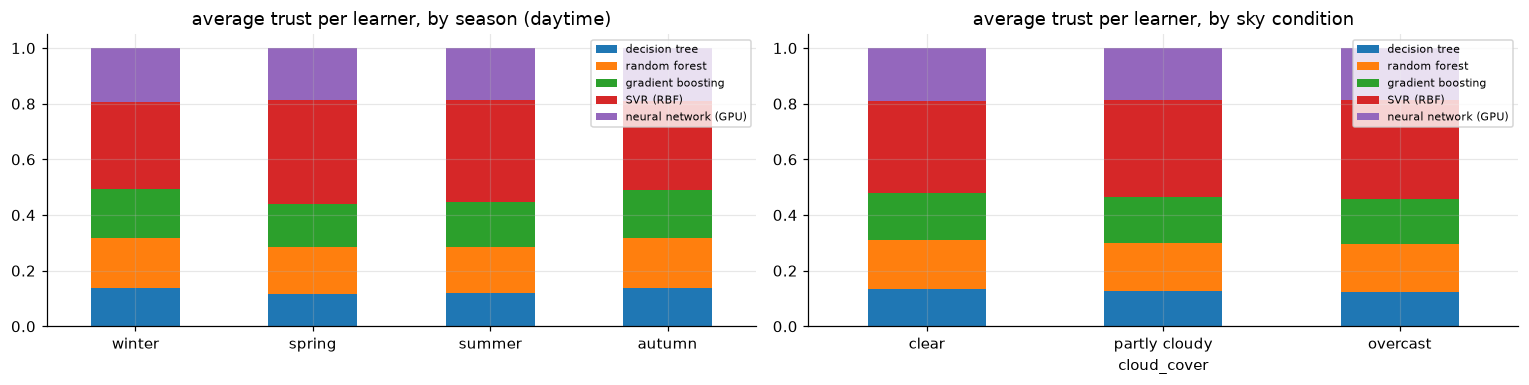

In [5]:
Wdf = pd.DataFrame(W, index=test.index, columns=names)
fig, ax = plt.subplots(1, 2, figsize=(14, 3.6))
Wdf[day].groupby(season[day]).mean().loc[["winter", "spring", "summer", "autumn"]].plot.bar(stacked=True, ax=ax[0], rot=0)
ax[0].set(title="average trust per learner, by season (daytime)"); ax[0].legend(fontsize=7)
Wdf[day].groupby(sky[day]).mean().plot.bar(stacked=True, ax=ax[1], rot=0)
ax[1].set(title="average trust per learner, by sky condition"); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

The meta network gives different weights in different regimes: that is the *dynamic selection* of the UK National
Grid design. Whether it beats a good single model depends on how different the learners' strengths are; on this data
compare the table above. Even when the gain is small, the weights are informative: they tell the operator which model
to trust in which weather.

## 4. Uncertainty: prediction intervals with quantile regression
Operators need a *range*, not just a number (to size reserves). Gradient boosting with the **pinball loss**
$L_\tau(y,q)=\max(\tau(y-q),(\tau-1)(y-q))$ predicts the $\tau$-quantile directly. We train $\tau=0.1$ and $0.9$ for an
80 % interval.

80 % interval: actual value inside the interval 77.8% of daytime hours (target 80 %)


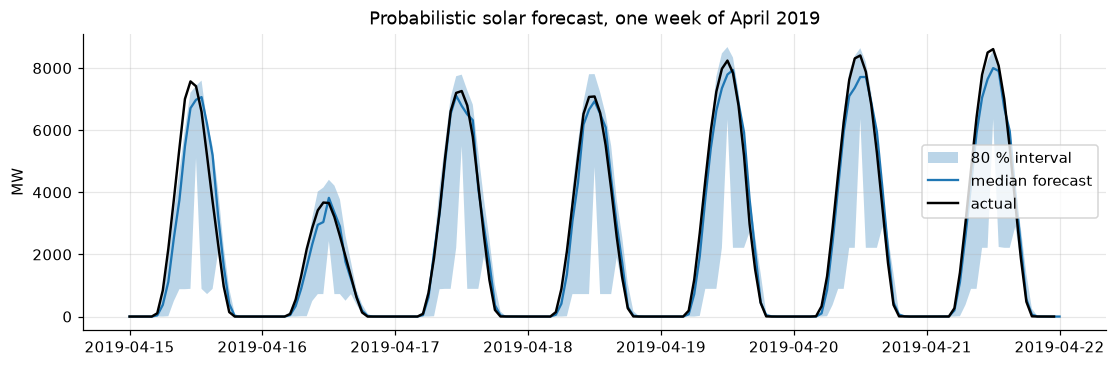

In [6]:
q = {}
for tau in (0.1, 0.5, 0.9):
    q[tau] = HistGradientBoostingRegressor(loss="quantile", quantile=tau, max_iter=500, learning_rate=0.05, random_state=0).fit(Xf, yf).predict(Xt).clip(0)
inside = ((yt.values >= q[0.1]) & (yt.values <= q[0.9]))[day.values].mean()
print(f"80 % interval: actual value inside the interval {inside:.1%} of daytime hours (target 80 %)")
wk = slice("2019-04-15", "2019-04-21")
m = test.index.to_series().between(*[pd.Timestamp(x, tz="UTC") for x in ("2019-04-15", "2019-04-22")]).values
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.fill_between(test.index[m], q[0.1][m], q[0.9][m], alpha=0.3, label="80 % interval")
ax.plot(test.index[m], q[0.5][m], label="median forecast"); ax.plot(yt.loc[wk], "k", lw=1.6, label="actual")
ax.set(title="Probabilistic solar forecast, one week of April 2019", ylabel="MW"); ax.legend(); plt.show()

## 5. Demand forecasting with recent-load features
The linear model of notebook 05 reached ~5 % MAPE. Recent history is very informative: for a **day-ahead** forecast we
may use the load of 24 h, 48 h and 168 h ago (known when the forecast is made) together with weather and calendar.

In [7]:
import holidays
hol = holidays.UK(subdiv="ENG", years=range(2016, 2020))
def load_feats(d):
    X = pd.DataFrame(index=d.index)
    for lag in (24, 48, 168):
        X[f"load_lag{lag}"] = df.load_mw.shift(lag).loc[d.index]
    X["load_mean_24_48"] = df.load_mw.shift(24).rolling(24).mean().loc[d.index]
    X["temperature"] = d.temperature_2m; X["temp_lag24"] = df.temperature_2m.shift(24).loc[d.index]
    X["hour"], X["dow"], X["doy_sin"], X["doy_cos"] = d.hour, d.dayofweek, d.doy_sin, d.doy_cos
    X["holiday"] = np.array([dt in hol for dt in d.index.date], dtype=float)
    X["xmas"] = (((d.month == 12) & (d.index.day >= 24)) | ((d.month == 1) & (d.index.day <= 2))).astype(float)
    X["solar_elev"] = d.solar_elevation; X["cloud"] = d.cloud_cover
    return X

trL, teL = df.loc["2017":"2018"], df.loc["2019"]
XLt, XLe = load_feats(trL), load_feats(teL)
gbL = HistGradientBoostingRegressor(max_iter=800, learning_rate=0.05, max_leaf_nodes=63, categorical_features=[XLt.columns.get_loc(c) for c in ("hour", "dow")],
                                    random_state=0).fit(XLt, trL.load_mw)
pL = gbL.predict(XLe)
mape = lambda y, p: 100 * np.mean(np.abs((y - p) / y))
print(f"day-ahead demand forecast 2019: gradient boosting MAPE = {mape(teL.load_mw.values, pL):.2f} %  "
      f"(seasonal naive {mape(teL.load_mw.values, df.load_mw.shift(168).loc[teL.index].values):.2f} %)")

day-ahead demand forecast 2019: gradient boosting MAPE = 3.45 %  (seasonal naive 6.09 %)


## Key takeaways
* Non-linear models clearly beat linear regression on solar (≈4 % vs ≈6 % nRMSE). Random forest and gradient
  boosting are the usual strong single models on tabular energy data (here the random forest was best).
* Different learners excel in different regimes: a context-aware meta-learner (the UK National Grid design) exploits
  that, and its weights explain which model to trust when.
* Always train the combiner on data the base learners did not see (validation period).
* Quantile models give calibrated intervals: check the coverage on the test set.
* For demand, recent load (lags) + calendar + weather with gradient boosting gives a large improvement over linear models.